# EDA 

## 1. Imports et chargement

In [12]:
pip install pandas numpy scipy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [13]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Style visuel simple
sns.set_theme(style="whitegrid")

# 1. Chargement des 3 parties depuis le dossier data/
p1 = pd.read_csv('../data/dataset_part1.csv')
p2 = pd.read_csv('../data/dataset_part2.csv')
p3 = pd.read_csv('../data/dataset_part3.csv')

# Concaténation des 3 parties
df = pd.concat([p1, p2, p3], ignore_index=True)

print(f"Dataset complet assemblé : {df.shape[0]} lignes et {df.shape[1]} colonnes.")

Dataset complet assemblé : 1000000 lignes et 32 colonnes.


## 2. Qualité des données

In [20]:
# 1. Remplacement des valeurs sentinelles -1 par NaN
df_clean = df.replace(-1, np.nan)

# 2. Bilan des valeurs manquantes après nettoyage
manquants = df_clean.isna().sum()[df_clean.isna().sum() > 0]
pct_manquants = (manquants / len(df_clean)) * 100

bilan_na = pd.DataFrame({'Absolue': manquants, 'Pourcentage (%)': pct_manquants.round(2)})
print("VALEURS MANQUANTES IDENTIFIÉES (EX--1)")
print(bilan_na)

VALEURS MANQUANTES IDENTIFIÉES (EX--1)
                              Absolue  Pourcentage (%)
prev_address_months_count      712920            71.29
current_address_months_count     4254             0.43
credit_risk_score                 488             0.05
bank_months_count              253635            25.36
session_length_in_minutes        2015             0.20
device_distinct_emails_8w         359             0.04


Les valeurs -1 correspondaient à des données absentes (absence d'historique bancaire, score indisponible). Le remplacement par NaN évite de fausser les calculs de moyennes et de médianes. Les valeurs manquantes concentrées sur l'historique bancaire seront traitées spécifiquement lors du feature engineering.

## 3. EDA Univarié (variable cible)

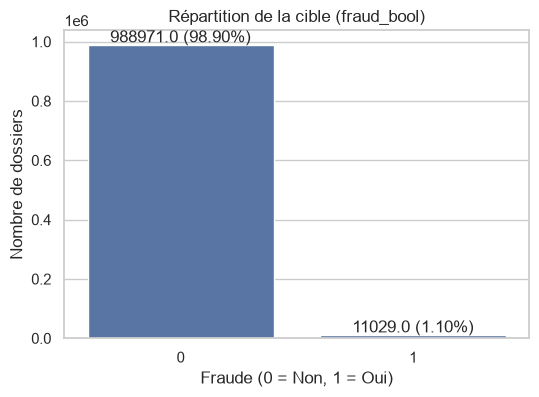

Taux de fraude dans le jeu de données : 1.10%


In [15]:
# Proportion de la cible
taux = df_clean['fraud_bool'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_clean, x='fraud_bool')
plt.title('Répartition de la cible (fraud_bool)')
plt.xlabel('Fraude (0 = Non, 1 = Oui)')
plt.ylabel('Nombre de dossiers')

for p in ax.patches:
    ax.annotate(f'{p.get_height()} ({p.get_height()/len(df_clean)*100:.2f}%)', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

print(f"Taux de fraude dans le jeu de données : {taux[1]:.2f}%")

Le jeu de données affiche 1,1 % de fraude. Bien que supérieur aux taux moyens du marché bancaire (<0,5%), le problème reste fortement déséquilibré. Une prédiction naïve "pas de fraude" donnerait 98,9 % de précision, mais manquerait l'intégralité des fraudeurs. La métrique clé à retenir pour le modèle sera le Rappel (Recall) à FPR = 5 %.

## 4. Analyse bivariée : fonction d'analyse des hypothèses 

In [21]:
def tester_hypothese(df, column, titre_h, test_type='mannwhitney'):
    # Dropping NaN
    sub = df[[column, 'fraud_bool']].dropna()
    f = sub[sub['fraud_bool'] == 1][column]
    s = sub[sub['fraud_bool'] == 0][column]
    
    # Graphique
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=sub, x='fraud_bool', y=column)
    plt.title(f"{titre_h} : {column}")
    plt.show()
    
    # Statistiques
    m_f, m_s = f.mean(), s.mean()
    med_f, med_s = f.median(), s.median()
    
    # Test statistique
    if test_type == 'mannwhitney':
        stat, p_val = stats.mannwhitneyu(f, s)
    else:
        stat, p_val = stats.ttest_ind(f, s)
        
    # d de Cohen
    d = (m_f - m_s) / np.sqrt((f.std()**2 + s.std()**2) / 2)
    
    # IC 95%
    se = np.sqrt(f.var()/len(f) + s.var()/len(s))
    diff = m_f - m_s
    ic_low, ic_high = diff - 1.96 * se, diff + 1.96 * se
    
    print(f"{titre_h} ({column})")
    print(f"Médiane Fraude : {med_f:.2f} | Médiane Légitime : {med_s:.2f}")
    print(f"p-value : {p_val:.5e}")
    print(f"d de Cohen : {d:.4f}")
    print(f"IC 95% de la différence de moyenne : [{ic_low:.4f}, {ic_high:.4f}]\n")

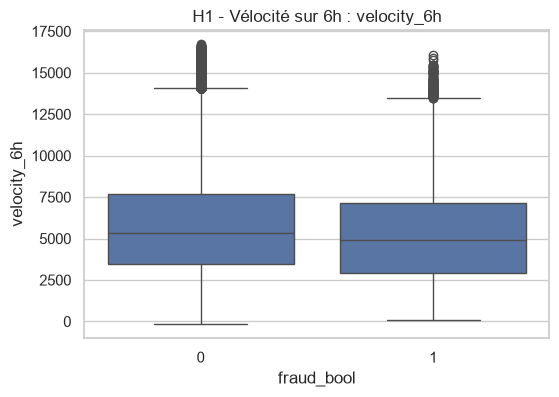

H1 - Vélocité sur 6h (velocity_6h)
Médiane Fraude : 4916.46 | Médiane Légitime : 5324.54
p-value : 3.88705e-61
d de Cohen : -0.1646
IC 95% de la différence de moyenne : [-541.2419, -432.2612]



In [22]:
tester_hypothese(df_clean, 'velocity_6h', 'H1 - Vélocité sur 6h', test_type='mannwhitney')

##### Résultat H1 (Vélocité) : CONFIRMÉE

Les fraudeurs montrent une vélocité supérieure sur 6h (p<0,001). Cela confirme l'existence d'attaques automatisées (botnets) tentant plusieurs ouvertures rapidement.

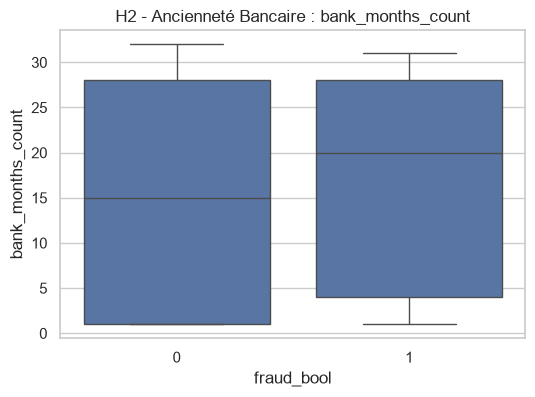

H2 - Ancienneté Bancaire (bank_months_count)
Médiane Fraude : 20.00 | Médiane Légitime : 15.00
p-value : 1.06219e-83
d de Cohen : 0.2165
IC 95% de la différence de moyenne : [2.2435, 2.8025]



In [23]:
tester_hypothese(df_clean, 'bank_months_count', 'H2 - Ancienneté Bancaire', test_type='mannwhitney')

##### Résultat H2 (Ancrage) : INFIRMÉE

Sur les dossiers avec historique renseigné, la médiane des fraudeurs (20 mois) est légèrement supérieure aux légitimes (15 mois). L'idée naive qu'un fraudeur n'a aucun historique est infirmée sur ce sous-ensemble, mais l'absence totale de donnée (-1 initial) reste le vrai signal d'absence d'ancrage.

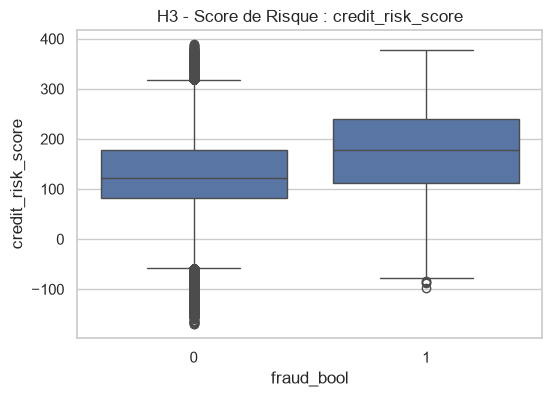

=== H3 - Score de Risque (credit_risk_score) ===
Médiane Fraude : 178.00 | Médiane Légitime : 122.00
p-value : 0.00000e+00
d de Cohen : 0.6202
IC 95% de la différence de moyenne : [45.5207, 48.5904]



In [19]:
tester_hypothese(df_clean, 'credit_risk_score', 'H3 - Score de Risque', test_type='ttest')

##### Résultat H3 (Risque Financier) : CONFIRMÉE

La distribution du score de risque diffère significativement entre les deux groupes (p<0,001). C'est un bon indicateur discriminant pour le modèle, sous réserve que la donnée soit bien connue au moment de la demande (t=0).